In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor

from sklearn.metrics import (mean_squared_error,mean_absolute_error,r2_score)

In [4]:
df=pd.read_csv(r"C:\Users\Shehan\OneDrive\Desktop\PROJECT_\data\cleaned_data.csv")
df.head()

,Month,Province,District,Household_Type,Household_Size,House_Area_m2,Bedrooms,AC_Units,Fans,Refrigerators,...,Other_High_Power_Appliances,Avg_Daily_AC_Hours,Avg_Daily_Fan_Hours,Avg_Daily_TV_Hours,Avg_Daily_Cooking_Hours,Solar_PV,Solar_Capacity_kW,Avg_Temperature_C,Previous_Month_kWh,Target_Monthly_kWh
0,January,Eastern,Ampara,Single_Family,4,69.1,1,1.0,4,1,...,3,5.1,4.7,3.5,3.3,No,0.0,30.3,369.7,350.8
1,January,Eastern,Ampara,Apartment,6,54.1,2,0.0,7,1,...,0,0.0,7.9,6.3,3.0,No,0.0,30.3,290.9,281.8
2,January,North Central,Anuradhapura,Single_Family,2,196.9,5,0.0,3,1,...,1,0.0,10.7,4.1,3.9,No,0.0,25.4,241.6,277.9
3,January,North Central,Anuradhapura,Single_Family,4,122.8,3,0.0,4,2,...,3,0.0,9.2,5.7,3.7,No,0.0,27.4,270.7,286.7
4,January,Uva,Badulla,Single_Family,5,93.9,2,0.0,5,1,...,2,0.0,4.7,2.7,1.4,No,0.0,29.6,307.3,303.0


In [5]:
x=df.drop(columns=["Target_Monthly_kWh"])
y=df["Target_Monthly_kWh"]

In [6]:
categorical_features=x.select_dtypes(include=["object"]).columns
numerical_features=x.select_dtypes(exclude=["object"]).columns

C:\Users\Shehan\AppData\Local\Temp\ipykernel_19500\1170186852.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features=x.select_dtypes(include=["object"]).columns


In [7]:
print("Categorical features:")
print(list(categorical_features))

print("\nNumerical features:")
print(list(numerical_features))

Categorical features:
['Month', 'Province', 'District', 'Household_Type', 'Solar_PV']

Numerical features:
['Household_Size', 'House_Area_m2', 'Bedrooms', 'AC_Units', 'Fans', 'Refrigerators', 'TVs', 'Washing_Machines', 'Water_Heaters', 'Computers', 'Other_High_Power_Appliances', 'Avg_Daily_AC_Hours', 'Avg_Daily_Fan_Hours', 'Avg_Daily_TV_Hours', 'Avg_Daily_Cooking_Hours', 'Solar_Capacity_kW', 'Avg_Temperature_C', 'Previous_Month_kWh']


In [8]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

In [9]:
preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numerical_features),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features)
    ]
)

In [10]:
linear_model=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",LinearRegression())
    ]
)

In [11]:
linear_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Month','Province','District',...,'Solar_Capacity_kW','Avg_Temperature_C', 'Previous_Month_kWh']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throu

In [12]:
linear_prediction=linear_model.predict(x_test)

In [13]:
linear_mae=mean_absolute_error(y_test,linear_prediction)
print("linear_regression_MAE:",linear_mae)

linear_regression_MAE: 24.38738626281116


In [14]:
linear_rmse=np.sqrt(mean_squared_error(y_test,linear_prediction))
print("linear_regression_RMSE:",linear_rmse)

linear_regression_RMSE: 29.833205103689224


In [15]:
linear_r2=r2_score(y_test,linear_prediction)
print("linear_regression_r2:",linear_r2)

linear_regression_r2: 0.883552641705747


In [16]:
decision_tree=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",DecisionTreeRegressor(random_state=42))
    ]
)

In [17]:
decision_tree.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Month','Province','District',...,'Solar_Capacity_kW','Avg_Temperature_C', 'Previous_Month_kWh']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throu

In [18]:
tree_prediction=decision_tree.predict(x_test)

In [19]:
tree_mae=mean_absolute_error(y_test,tree_prediction)
print("decision_tree_MAE:",tree_mae)

tree_rmse=np.sqrt(mean_squared_error(y_test,tree_prediction))
print("decision_tree_RSME:",tree_rmse)

tree_r2=r2_score(y_test,tree_prediction)
print("decision_tree_r2:",tree_r2)

decision_tree_MAE: 41.132000000000005
decision_tree_RSME: 52.74957061436614
decision_tree_r2: 0.6359444381013016


In [20]:
random_forest=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",RandomForestRegressor(n_estimators=200,random_state=42))
    ]
)

In [21]:
random_forest.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Month','Province','District',...,'Solar_Capacity_kW','Avg_Temperature_C', 'Previous_Month_kWh']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throu

In [22]:
random_forest_prediction=random_forest.predict(x_test)

In [23]:
rf_mae=mean_absolute_error(y_test,random_forest_prediction)
print("random forest MAE:",rf_mae)

rf_rmse=np.sqrt(mean_squared_error(y_test,random_forest_prediction))
print("random forest RMSE:",rf_rmse)

rf_r2=r2_score(y_test,random_forest_prediction)
print("random forest r2:",rf_r2)

random forest MAE: 30.136477499999984
random forest RMSE: 37.5150897188218
random forest r2: 0.81586269115598


In [24]:
gradient_boosting=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",GradientBoostingRegressor(random_state=42))
    ]
)

In [25]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.20,random_state=42)

In [26]:
gradient_boosting.fit( x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Month','Province','District',...,'Solar_Capacity_kW','Avg_Temperature_C', 'Previous_Month_kWh']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throu

In [27]:
gb_predictions = gradient_boosting.predict(x_test)

In [28]:
gb_mae = mean_absolute_error(y_test,gb_predictions)

gb_rmse = np.sqrt( mean_squared_error(y_test,gb_predictions))

gb_r2 = r2_score(y_test,gb_predictions)

print("Gradient Boosting MAE :", gb_mae)
print("Gradient Boosting RMSE:", gb_rmse)
print("Gradient Boosting R²   :", gb_r2)

Gradient Boosting MAE : 28.74183160602869
Gradient Boosting RMSE: 36.67831947928174
Gradient Boosting R²   : 0.823985408970897


In [29]:
result=pd.DataFrame({
    "model":["linear regression","decision tree","random forest","gradient boosting"],
    "MAE":[linear_mae,tree_mae,rf_mae,gb_mae],
    "RMSE":[linear_rmse,tree_rmse,rf_rmse,gb_rmse],
    "R2_SCORE":[linear_r2,tree_r2,rf_r2,gb_r2]
})
result

,model,MAE,RMSE,R2_SCORE
0,linear regression,24.387386,29.833205,0.883553
1,decision tree,41.132000,52.749571,0.635944
2,random forest,30.136477,37.515090,0.815863
3,gradient boosting,28.741832,36.678319,0.823985


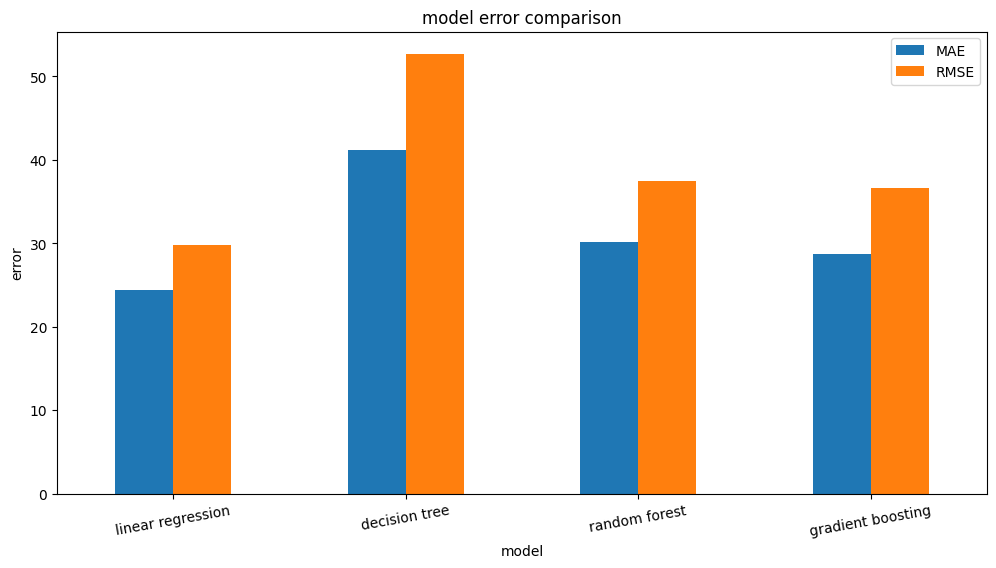

In [30]:
result.plot(x="model",y=["MAE","RMSE"],kind="bar",figsize=(12,6))

plt.title("model error comparison")
plt.ylabel("error")
plt.xticks(rotation=10)
plt.show()

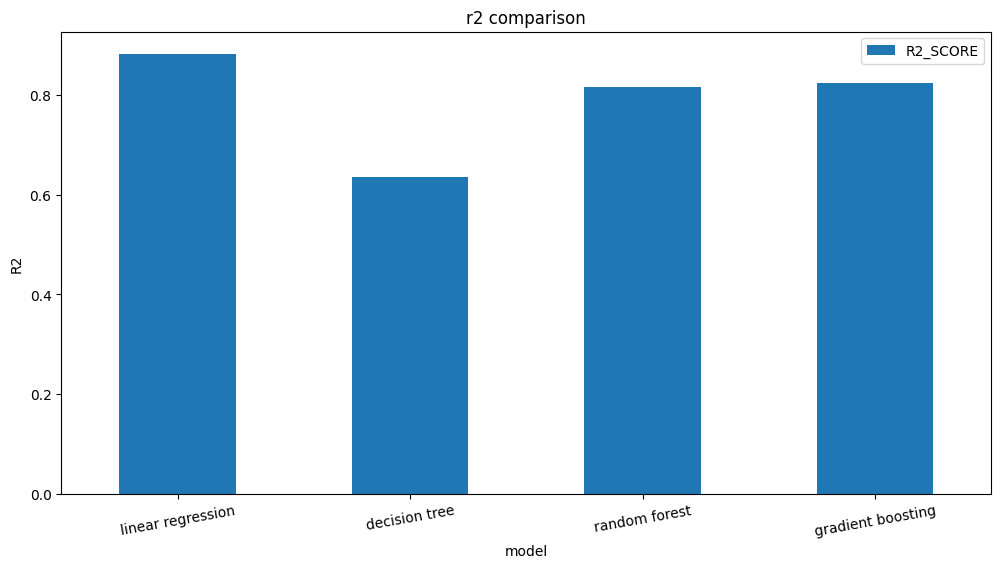

In [31]:
result.plot(x="model",y="R2_SCORE",kind="bar",figsize=(12,6))

plt.title("r2 comparison")
plt.ylabel("R2")
plt.xticks(rotation=10)
plt.show()